# Detecting unfamiliar inputs with SNGP

Make a classifier's confidence drop on inputs unlike its training data, in a single forward pass.

Show a clothing classifier a handwritten digit and it will still answer, often with high
confidence: a standard network has no notion of "I have never seen anything like this".

The **Spectral-normalized Neural Gaussian Process** ([SNGP](https://arxiv.org/abs/2006.10108))
makes a network *distance aware* with two changes:

1. [`SpectralNormalization`](https://anas-rz.github.io/keras-proba/api/layers/#keras_proba.layers.SpectralNormalization)
   on the hidden layers, so that inputs far apart stay far apart in the hidden features;
2. a Gaussian process output layer, whose confidence drops with the distance from the training
   data ([`GaussianProcessClassificationHead`](https://anas-rz.github.io/keras-proba/api/layers/#keras_proba.layers.GaussianProcessClassificationHead)).

We train both networks on Fashion-MNIST, then show them MNIST digits they have never seen.

In [ ]:
# Install keras-proba, then choose a backend: "jax", "tensorflow" or "torch".
!pip install -q keras-proba
import os

os.environ["KERAS_BACKEND"] = "jax"

## Load the data

[Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) images of clothing (10
classes) for training and testing, and [MNIST](https://yann.lecun.com/exdb/mnist/) digits as
unfamiliar inputs.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

import keras
import keras_proba

(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
(_, _), (x_digits, _) = keras.datasets.mnist.load_data()
x_train, x_test, x_digits = (images.reshape(len(images), -1).astype("float32") / 255 for images in (x_train, x_test, x_digits))

## Two networks with the same backbone

A residual multi-layer network. The SNGP version wraps each hidden layer in
`SpectralNormalization` and replaces the output layer with the Gaussian process head.

In [3]:
def build(sngp):
    inputs = keras.Input((784,))
    hidden = keras.layers.Dense(256)(inputs)
    for _ in range(3):
        layer = keras.layers.Dense(256, activation="relu")
        if sngp:
            layer = keras_proba.layers.SpectralNormalization(layer, norm_multiplier=0.95, mode="reparameterization")
        hidden = hidden + keras.layers.Dropout(0.1)(layer(hidden))
    if sngp:
        logits = keras_proba.layers.GaussianProcessClassificationHead(
            inner_dim=0, num_classes=10, scale_random_features=True, temperature=np.pi / 8, gp_cov_momentum=-1
        )(hidden)
    else:
        logits = keras.layers.Dense(10)(hidden)
    model = keras.Model(inputs, logits)
    model.compile(optimizer="adam", loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
    return model


keras.utils.set_random_seed(0)
standard = build(sngp=False)
standard.fit(x_train, y_train, epochs=10, batch_size=128, verbose=0)

keras.utils.set_random_seed(0)
sngp = build(sngp=True)
# The Gaussian process estimates its uncertainty from the training features; reset it at every
# epoch so that it reflects the final features.
sngp.fit(x_train, y_train, epochs=10, batch_size=128, verbose=0, callbacks=[keras_proba.callbacks.ResetCovarianceCallback()])

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


## Confidence on clothing and on digits

The confidence of a prediction is its highest class probability. Both networks are about
equally accurate on clothing, and confident on it. On digits, the standard network is often
still confident; SNGP's confidence drops, mostly below 0.5.

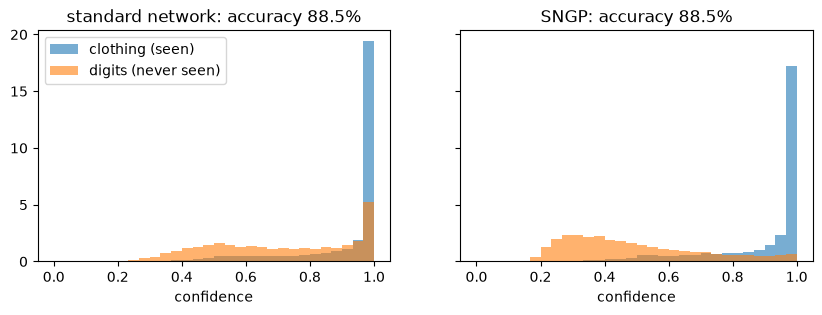

In [4]:
def confidence(model, x):
    return keras.ops.convert_to_numpy(keras.ops.max(keras.ops.softmax(model.predict(x, batch_size=512, verbose=0)), axis=-1))


fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, (name, model) in zip(axes, [("standard network", standard), ("SNGP", sngp)]):
    accuracy = (model.predict(x_test, batch_size=512, verbose=0).argmax(-1) == y_test).mean()
    ax.hist(confidence(model, x_test), bins=30, range=(0, 1), alpha=0.6, density=True, label="clothing (seen)")
    ax.hist(confidence(model, x_digits), bins=30, range=(0, 1), alpha=0.6, density=True, label="digits (never seen)")
    ax.set(title=f"{name}: accuracy {accuracy:.1%}", xlabel="confidence")
axes[0].legend()
plt.show()

## How well does the confidence separate digits from clothing?

The AUROC is the probability that a random digit gets a lower confidence than a random clothing
image: 0.5 is chance, 1.0 is perfect separation.

In [5]:
def auroc(familiar, unfamiliar):
    ranks = np.concatenate([familiar, unfamiliar]).argsort().argsort() + 1
    n, m = len(familiar), len(unfamiliar)
    return (ranks[:n].sum() - n * (n + 1) / 2) / (n * m)


for name, model in [("standard network", standard), ("SNGP", sngp)]:
    print(f"{name}: AUROC {auroc(confidence(model, x_test), confidence(model, x_digits)):.3f}")

standard network: AUROC 0.809


SNGP: AUROC 0.926


## What we learned

- A standard network is confident even on inputs unlike anything it was trained on.
- SNGP keeps the accuracy and makes the confidence drop for unfamiliar inputs, in a single
  forward pass: no ensembles, no repeated sampling.
- The recipe: `SpectralNormalization` on the hidden layers, a `GaussianProcessClassificationHead`
  as output, and the `ResetCovarianceCallback` during training. See the
  [SNGP guide](https://anas-rz.github.io/keras-proba/guides/sngp/) for the details.